In [7]:
using Combinatorics
using Plots
using Random
using LinearAlgebra

In [8]:
function calculate_MFPT(b::Vector{Float64})
    N_minus_1 = length(b)
    tau = zeros(Float64, N_minus_1)
    tau[1] = 1.0 / b[1]
    for m in 2:N_minus_1
        x_m = (1.0 - b[m]) / b[m]
        tau[m] = (1.0 / b[m]) + x_m * tau[m-1]
    end
    return sum(tau)
end

function calculate_second_moment(b::Vector{Float64}, d::Vector{Float64})
    n_minus_1 = length(b)
    ratios = d ./ b

    inner_sums = zeros(Float64, n_minus_1)
    inner_sums[1] = 1.0 / b[1]
    for k in 2:n_minus_1
        inner_sums[k] = 1.0 / b[k] + ratios[k] * inner_sums[k - 1]
    end

    suffix_sums = zeros(Float64, n_minus_1 + 1)
    for index in n_minus_1:-1:1
        suffix_sums[index] = suffix_sums[index + 1] + inner_sums[index]
    end

    second_sum = 0.0
    for m in 1:n_minus_1
        for i in 1:m
            product = 1.0
            for j in (i + 1):m
                product *= ratios[j]
            end
            second_sum += (1.0 / b[i]) * suffix_sums[i] * product
        end
    end

    return 2.0 * second_sum - calculate_MFPT(b)
end

calculate_second_moment (generic function with 1 method)

In [12]:
function find_optimal_permutations(base_b::Vector{Float64})
    N = length(base_b) + 1
    all_perms = collect(permutations(1:(N-1)))
    n_states = length(all_perms)

    min_mfpt = Inf
    min_variance = Inf
    best_permutation_mfpt = []
    best_permutation_var = []

    for p in all_perms
        b = base_b[p]
        mfpt = calculate_MFPT(b)
        if mfpt < min_mfpt
            min_mfpt = mfpt
            best_permutation_mfpt = b
        end
        second_moment = calculate_second_moment(b, 1.0 .- b)
        variance = second_moment - mfpt^2
        if variance < min_variance
            min_variance = variance
            best_permutation_var = b
        end
    end
    return best_permutation_mfpt, min_mfpt, best_permutation_var, min_variance
end

find_optimal_permutations (generic function with 1 method)

In [21]:
base_b = rand(11)
best_perm_mfpt, min_mfpt, best_perm_var, min_variance = find_optimal_permutations(base_b)
println("Best permutation for minimum MFPT: ", best_perm_mfpt)
println("Minimum MFPT: ", min_mfpt)
println("Best permutation for minimum variance: ", best_perm_var)
println("Minimum variance: ", min_variance)

Best permutation for minimum MFPT: [0.013925869900180743, 0.2044042887179328, 0.48285195396630354, 0.2835017619072434, 0.860617354137337, 0.2029106024688211, 0.7432630579098247, 0.4038761837765056, 0.5579210941913487, 0.07411257942109994, 0.055295779906586184]
Minimum MFPT: 50261.828535612716
Best permutation for minimum variance: [0.013925869900180743, 0.2029106024688211, 0.48285195396630354, 0.2835017619072434, 0.860617354137337, 0.2044042887179328, 0.7432630579098247, 0.4038761837765056, 0.5579210941913487, 0.07411257942109994, 0.055295779906586184]
Minimum variance: 2.5157941829420557e9


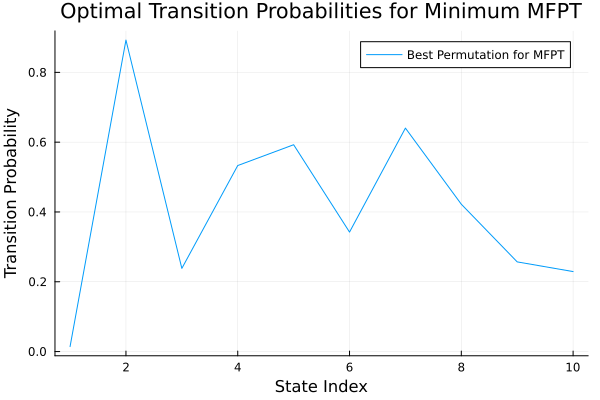

In [18]:
plot(best_perm_mfpt, label="Best Permutation for MFPT", xlabel="State Index", ylabel="Transition Probability", title="Optimal Transition Probabilities for Minimum MFPT")


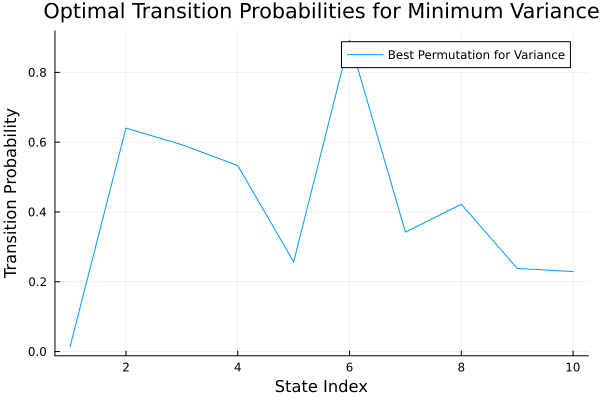

In [19]:
plot(best_perm_var, label="Best Permutation for Variance", xlabel="State Index", ylabel="Transition Probability", title="Optimal Transition Probabilities for Minimum Variance")

In [33]:
base_b = [0.5 for i in 1:10]
base_b[1] = 0.9
base_b[2] = 0.4
best_perm_mfpt, min_mfpt, best_perm_var, min_variance = find_optimal_permutations(base_b)
println("Best permutation for minimum MFPT: ", best_perm_mfpt)
println("Minimum MFPT: ", min_mfpt)
println("Best permutation for minimum variance: ", best_perm_var)
println("Minimum variance: ", min_variance)

Best permutation for minimum MFPT: [0.4, 0.5, 0.5, 0.5, 0.5, 0.9, 0.5, 0.5, 0.5, 0.5]
Minimum MFPT: 63.88888888888889
Best permutation for minimum variance: [0.4, 0.5, 0.5, 0.5, 0.5, 0.9, 0.5, 0.5, 0.5, 0.5]
Minimum variance: 1634.5679012345709


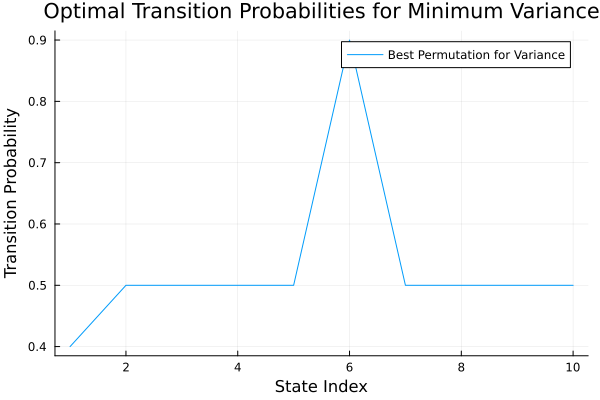

In [34]:
plot(best_perm_mfpt, label="Best Permutation for MFPT", xlabel="State Index", ylabel="Transition Probability", title="Optimal Transition Probabilities for Minimum MFPT")
plot(best_perm_var, label="Best Permutation for Variance", xlabel="State Index", ylabel="Transition Probability", title="Optimal Transition Probabilities for Minimum Variance")